# 02 Features: receiver-side account state

Work card 02. Runs `AccountState` over all dense days in time order, so every feature uses only earlier transactions. Fraud labels act as confirmed reports: they flag accounts 24 h later, and only labels from the training period are used.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_transactions, drop_sparse_days, time_split
from src.features import FEATURE_NAMES, build_feature_table

## Unit check on hand-made transactions

M receives from A, B, C, sends 200 to X, then receives from D two hours later. A→M is labelled laundering, but the flag only arrives 24 h later.

In [2]:
t0 = pd.Timestamp('2022-09-01 00:00')
toy = pd.DataFrame({
    'ts': [t0, t0 + pd.Timedelta('10min'), t0 + pd.Timedelta('20min'), t0 + pd.Timedelta('30min'), t0 + pd.Timedelta('2h')],
    'src': ['A', 'B', 'C', 'M', 'D'],
    'dst': ['M', 'M', 'M', 'X', 'M'],
    'amount': [100.0, 50.0, 70.0, 200.0, 10.0],
    'amount_paid': [100.0, 50.0, 70.0, 200.0, 10.0],
    'payment_format': ['ACH'] * 5,
    'receiving_currency': ['US Dollar'] * 5,
    'payment_currency': ['US Dollar'] * 5,
    'label': [1, 0, 0, 0, 0],
})
f, _ = build_feature_table(toy, progress_every=0)

assert f.loc[2, 'dst_in_count_1h'] == 2 and f.loc[2, 'dst_unique_senders_24h'] == 2
assert f.loc[3, 'dst_minutes_since_first_seen'] == -1 and f.loc[3, 'src_out_count_24h'] == 0
assert f.loc[4, 'dst_in_count_1h'] == 0 and f.loc[4, 'dst_in_count_24h'] == 3
assert f.loc[4, 'dst_unique_senders_24h'] == 3 and f.loc[4, 'dst_out_count_24h'] == 1
assert abs(f.loc[4, 'dst_pass_through_24h'] - 200 / 220) < 1e-5
assert f.loc[4, 'dst_flagged'] == 0  # label not yet 'reported'
print('Unit check passed')
f[['dst_in_count_1h', 'dst_in_count_24h', 'dst_unique_senders_24h', 'dst_out_count_24h', 'dst_pass_through_24h', 'dst_flagged']]

Unit check passed


,dst_in_count_1h,dst_in_count_24h,dst_unique_senders_24h,dst_out_count_24h,dst_pass_through_24h,dst_flagged
0,0.0,0.0,0.0,0.0,0.000000,0.0
1,1.0,1.0,1.0,0.0,0.000000,0.0
2,2.0,2.0,2.0,0.0,0.000000,0.0
3,0.0,0.0,0.0,0.0,0.000000,0.0
4,0.0,3.0,3.0,1.0,0.909091,0.0


## Load features for all dense days

The full build takes several minutes, so it runs as a background script in the **Jupyter terminal**, not in this notebook (a closed tab or Stop button would kill it):

```bash
cd ~/shared/trustpause
nohup python -m src.features > data/features_build.log 2>&1 &
tail -f data/features_build.log
```

Wait for `Saved .../features_all.pkl` (Ctrl+C stops `tail`, not the build), then run the cells below.

In [3]:
features = pd.read_pickle(ROOT / 'data' / 'features_all.pkl')
train_end = features.loc[features['split'] == 'train', 'ts'].max()
print(f'Loaded {len(features):,} rows; training labels used up to {train_end}')
print(f'Feature table memory: {features.memory_usage(deep=True).sum() / 1e9:.2f} GB')
print((ROOT / 'data' / 'features_build.log').read_text()[-600:])

Loaded 5,077,237 rows; training labels used up to 2022-09-06 23:59:00
Feature table memory: 0.80 GB
,000 rows  31s  (20.6 µs/row)
2,000,000 rows  47s  (23.4 µs/row)
2,500,000 rows  61s  (24.5 µs/row)
3,000,000 rows  73s  (24.4 µs/row)
3,500,000 rows  87s  (24.9 µs/row)
4,000,000 rows  100s  (25.0 µs/row)
4,500,000 rows  112s  (24.8 µs/row)
5,000,000 rows  127s  (25.4 µs/row)
Built 5,077,237 rows in 131s (25.8 µs per transaction)
Accounts tracked: 515,078; flagged accounts: 3,471
Saved /home/ibm-user/shared/trustpause/data/features_all.pkl
          size   sum      mean
split                         
train  3248921  2530  0.000779
val     965524  1036  0.001073
test    862792   956  0.001108



In [4]:
features.groupby('split', sort=False)['label'].agg(['size', 'sum', 'mean'])

,size,sum,mean
split,,,
train,3248921,2530,0.000779
val,965524,1036,0.001073
test,862792,956,0.001108


## Leakage check

Features for the first 100,000 rows must be identical whether or not later rows exist.

In [5]:
df = load_transactions(ROOT / 'data' / 'HI-Small_Trans.csv')
dense_head = drop_sparse_days(df).iloc[:100_000]
del df
head, _ = build_feature_table(dense_head, label_cutoff=train_end, progress_every=0)
same = np.allclose(head[FEATURE_NAMES].values, features[FEATURE_NAMES].iloc[:100_000].values)
print('No look-ahead:', same)
assert same

No look-ahead: True


## Fraud vs normal (training period)

In [6]:
tr = features[features['split'] == 'train']
comparison = tr.groupby('label')[FEATURE_NAMES].mean().T
comparison.columns = ['normal_mean', 'laundering_mean']
comparison['ratio'] = comparison['laundering_mean'] / comparison['normal_mean'].replace(0, np.nan)
comparison.sort_values('ratio', ascending=False)

,normal_mean,laundering_mean,ratio
dst_flagged,0.002853,0.144664,50.705681
dst_flagged_receivers_24h,0.005196,0.067589,13.007298
src_flagged,0.064214,0.290514,4.524168
dst_flagged_senders_24h,0.068546,0.292490,4.267085
payment_format,1.884050,3.661265,1.943295
src_unique_receivers_24h,328.787109,626.917786,1.906759
src_out_count_24h,751.867554,1428.294067,1.899662
dst_unique_senders_24h,1.397573,1.919368,1.373358
dst_minutes_since_first_seen,3174.866699,4346.889160,1.369156
log_amount,7.465005,8.927249,1.195880


In [7]:
bands = pd.cut(tr['dst_unique_senders_24h'], [-1, 0, 1, 2, 5, 10, 50, np.inf])
fan_in = tr.groupby(bands, observed=True)['label'].agg(transactions='size', laundering_rate='mean')
fan_in['laundering_rate_%'] = (100 * fan_in.pop('laundering_rate')).round(3)
fan_in

,transactions,laundering_rate_%
dst_unique_senders_24h,,
"(-1.0, 0.0]",781987,0.093
"(0.0, 1.0]",1400910,0.060
"(1.0, 2.0]",786521,0.054
"(2.0, 5.0]",249548,0.164
"(5.0, 10.0]",10305,0.805
"(10.0, 50.0]",17128,0.239
"(50.0, inf]",2522,0.159


In [8]:
for col in ['src_flagged', 'dst_flagged', 'sender_known_to_dst_24h', 'cross_currency', 'is_self_transfer']:
    rates = tr.groupby(col)['label'].agg(['size', 'mean'])
    rates['mean'] = (100 * rates['mean']).round(3)
    print(col)
    print(rates.rename(columns={'mean': 'laundering_rate_%'}), '\n')

src_flagged
                size  laundering_rate_%
src_flagged                            
0.0          3039723              0.059
1.0           209198              0.351 

dst_flagged
                size  laundering_rate_%
dst_flagged                            
0.0          3239293              0.067
1.0             9628              3.801 

sender_known_to_dst_24h
                            size  laundering_rate_%
sender_known_to_dst_24h                            
0.0                      1425106              0.146
1.0                      1823815              0.025 

cross_currency
                   size  laundering_rate_%
cross_currency                            
0.0             3205824              0.079
1.0               43097              0.000 

is_self_transfer
                     size  laundering_rate_%
is_self_transfer                            
0.0               2696535              0.094
1.0                552386              0.001 



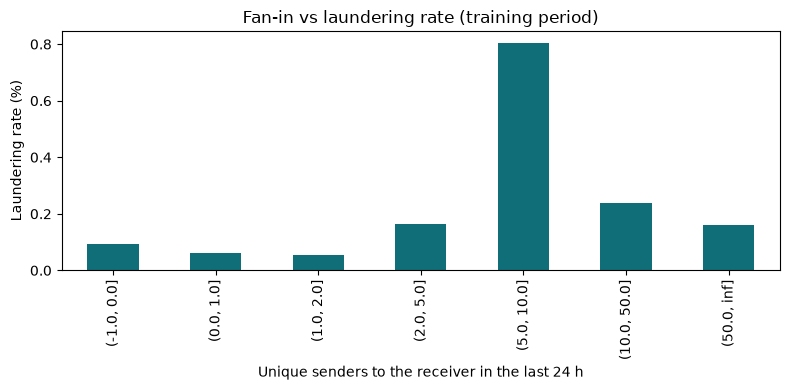

In [9]:
try:
    import matplotlib.pyplot as plt
    ax = fan_in['laundering_rate_%'].plot(kind='bar', figsize=(8, 4), color='#0F6E78')
    ax.set_xlabel('Unique senders to the receiver in the last 24 h')
    ax.set_ylabel('Laundering rate (%)')
    ax.set_title('Fan-in vs laundering rate (training period)')
    plt.tight_layout()
    (ROOT / 'screenshots').mkdir(exist_ok=True)
    plt.savefig(ROOT / 'screenshots' / 'fan_in_vs_laundering.png', dpi=150)
    plt.show()
except ImportError:
    print('matplotlib not installed; skip chart')